# Quanto grande fare ogni passo, e perche' non sempre uguale

*Anatomia di un LLM* · capitolo 6, Addestrarlo · script `05-04`, `scripts/05_04_schedule_lr.py`

Il tasso di apprendimento decide di quanto si sposta il modello a ogni
correzione. Tenerlo fisso funziona male in due momenti opposti: all'inizio,
quando l'ottimizzatore non ha ancora idea di quanto siano grandi i gradienti,
e alla fine, quando servono aggiustamenti fini e non salti.

Si esegue con `python3 scripts/05_04_schedule_lr.py`
e dura circa 35 secondi.

> **Per riottenere i numeri del libro** esegui le celle in ordine, dalla prima. Il seme si fissa una volta sola, in `prepara()`: rieseguire una cella a metà cambia i numeri casuali di tutte quelle dopo.

[Apri in Colab](https://colab.research.google.com/github/fcollova/llm-anatomy/blob/main/notebooks/05_04_schedule_lr.ipynb) · la prima cella scarica il codice, se non lo trova accanto.

In [1]:
# Porta il notebook nella cartella che contiene llm_anatomy/, da dovunque
# sia stato aperto: gli script si eseguono da li', e cosi' anche le celle.
import os
import subprocess
import sys
from pathlib import Path

radice = next((p for p in [Path.cwd(), *Path.cwd().parents]
               if (p / "llm_anatomy").is_dir()), None)

if radice is None:
    # Il notebook e' stato aperto da solo, per esempio su Colab: il codice, il
    # testo e il modello addestrato si scaricano una volta, qui accanto.
    REPO, RAMO, CARTELLA = "fcollova/llm-anatomy", "main", ""
    copia = Path("anatomia-di-un-llm")
    if not copia.exists():
        esito = subprocess.run(
            ["git", "clone", "-q", "--depth", "1", "--branch", RAMO,
             f"https://github.com/{REPO}.git", str(copia)], capture_output=True)
        if esito.returncode != 0:
            raise SystemExit("Non riesco a scaricare il codice da github.com/"
                             + REPO + ": " + esito.stderr.decode()[-300:])
    radice = copia / CARTELLA

os.chdir(radice)
sys.path.insert(0, str(Path.cwd()))

In [2]:
import math

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import torch

from llm_anatomy.config import AgoGPTConfig
from llm_anatomy.data import get_batch, prepara_split
from llm_anatomy.model import AgoGPT
from llm_anatomy.train import ConfigAddestramento, lr_al_passo
from llm_anatomy.utils import (dec, figura, prepara, stile_figure, tabella,
                               titolo, verifica)

prepara()

PASSI = 600     # un addestramento corto, per poterlo rifare tre volte
WARMUP = 60     # i primi dieci per cento salgono da zero
LR = 3e-3       # il valore di crociera


# Sale in linea retta per WARMUP passi, poi scende come un quarto di coseno
# fino a un decimo del valore di crociera. E' la forma usata quasi ovunque.
def coseno(passo: int) -> float:
    if passo < WARMUP:
        return LR * (passo + 1) / WARMUP
    avanzamento = (passo - WARMUP) / (PASSI - WARMUP)
    return LR * (0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * avanzamento)))


def radice_inversa(passo: int, d_model: int = 512) -> float:
    """La formula del paper 2017: lrate = d^-0.5 * min(s^-0.5, s * warmup^-1.5)."""
    s = passo + 1
    return d_model ** -0.5 * min(s ** -0.5, s * WARMUP ** -1.5)


def costante(passo: int) -> float:
    return LR

[ambiente] torch 2.13.0+cpu  device=cpu  threads=8  seed=1337


In [3]:
titolo("Tre modi di scegliere il passo")
righe = []
for passo in (0, 10, WARMUP - 1, WARMUP, 200, 400, PASSI - 1):
    righe.append([passo,
                  f"{coseno(passo):.2e}",
                  f"{radice_inversa(passo):.2e}",
                  f"{costante(passo):.2e}"])
tabella(["passo", "coseno + warmup", "radice inversa (2017)", "costante"],
        righe)
print("  la radice inversa e' scritta con la normalizzazione del paper,")
print("  quindi su una scala diversa: cio' che conta e' la forma, non il")
print("  valore")


Tre modi di scegliere il passo
------------------------------
passo  coseno + warmup  radice inversa (2017)  costante
-----  ---------------  ---------------------  --------
0             5.00e-05               9.51e-05  3.00e-03
10            5.50e-04               1.05e-03  3.00e-03
59            3.00e-03               5.71e-03  3.00e-03
60            3.00e-03               5.66e-03  3.00e-03
200           2.58e-03               3.12e-03  3.00e-03
400           1.12e-03               2.21e-03  3.00e-03
599           3.00e-04               1.80e-03  3.00e-03
  la radice inversa e' scritta con la normalizzazione del paper,
  quindi su una scala diversa: cio' che conta e' la forma, non il
  valore


In [4]:
titolo("Perche' non si parte a tutta velocita'")
print("  ad Adam servono alcuni passi per stimare i momenti del gradiente.")
print("  Nei primissimi passi la stima e' rumorosa, e un tasso pieno la")
print("  trasforma in aggiornamenti enormi. Il warmup non e' scaramanzia: e'")
print("  il tempo che si concede all'ottimizzatore per misurare la scala dei")
print("  gradienti")
verifica(coseno(0) < coseno(WARMUP) / 10,
         "il tasso al primo passo e' meno di un decimo di quello a regime")
verifica(abs(coseno(PASSI - 1) - 0.1 * LR) < 0.02 * LR,
         "alla fine il coseno si e' ridotto al 10% del valore massimo, come previsto")


Perche' non si parte a tutta velocita'
--------------------------------------
  ad Adam servono alcuni passi per stimare i momenti del gradiente.
  Nei primissimi passi la stima e' rumorosa, e un tasso pieno la
  trasforma in aggiornamenti enormi. Il warmup non e' scaramanzia: e'
  il tempo che si concede all'ottimizzatore per misurare la scala dei
  gradienti
  [verifica superata] il tasso al primo passo e' meno di un decimo di quello a
                      regime
  [verifica superata] alla fine il coseno si e' ridotto al 10% del valore
                      massimo, come previsto


In [5]:
titolo("La differenza, misurata")
_, dati_train, dati_val = prepara_split()
cfg = AgoGPTConfig(vocab_size=93, block_size=64, n_layer=2, d_model=96,
                   n_head=4)
tc = ConfigAddestramento(passi=PASSI, batch_size=16, lr=LR, warmup=WARMUP)

risultati = {}
for nome, schedule in (("coseno + warmup", coseno),
                       ("costante", costante),
                       ("costante senza warmup, 3x", lambda p: 3 * LR)):
    torch.manual_seed(1337)
    modello = AgoGPT(cfg)
    ott = torch.optim.AdamW(modello.parameters(), lr=LR, betas=(0.9, 0.95),
                            weight_decay=0.1)
    gen = torch.Generator().manual_seed(1337)
    storia = []
    for passo in range(PASSI):
        for gruppo in ott.param_groups:
            gruppo["lr"] = schedule(passo)      # il tasso di questo passo
        x, y = get_batch(dati_train, tc.batch_size, cfg.block_size, gen)
        _, perdita = modello(x, y)
        ott.zero_grad(set_to_none=True)
        perdita.backward()
        torch.nn.utils.clip_grad_norm_(modello.parameters(), 1.0)
        ott.step()
        if (passo + 1) % 20 == 0:
            storia.append(perdita.item())
    gen_eval = torch.Generator().manual_seed(4242)
    with torch.no_grad():
        perdite = []
        for _ in range(20):
            x, y = get_batch(dati_val, tc.batch_size, cfg.block_size, gen_eval)
            _, p = modello(x, y)
            perdite.append(float(p))
    risultati[nome] = (storia, sum(perdite) / len(perdite))

righe = [[nome, dec(storia[0], 3), dec(storia[-1], 3), dec(val, 4)]
         for nome, (storia, val) in risultati.items()]
tabella(["schedule", "perdita a 20 passi", "a fine corsa", "validazione"],
        righe)

migliore = min(risultati, key=lambda k: risultati[k][1])
print(f"  il migliore e' '{migliore}'")
verifica(risultati["coseno + warmup"][1] <= risultati["costante"][1],
         "il coseno con warmup non fa peggio del tasso costante")
divario = risultati["costante"][1] - risultati["coseno + warmup"][1]
print(f"  il divario sulla validazione e' {dec(divario, 4)} nat: piccolo in")
print("  valore assoluto, e nella stessa direzione a ogni scala. La coda a")
print("  tasso basso serve a rifinire, la fase a tasso alto a non fermarsi")
print("  nel primo minimo incontrato, e il warmup a non rovinare i primi")
print("  passi:")
triplo = risultati["costante senza warmup, 3x"][1]
print(f"  il tasso triplo senza warmup chiude a {dec(triplo, 4)}")


La differenza, misurata
-----------------------


schedule                   perdita a 20 passi  a fine corsa  validazione
-------------------------  ------------------  ------------  -----------
coseno + warmup                         3,436         1,629       1,7618
costante                                3,030         1,739       1,8106
costante senza warmup, 3x               3,101         1,904       1,9913
  il migliore e' 'coseno + warmup'
  [verifica superata] il coseno con warmup non fa peggio del tasso costante
  il divario sulla validazione e' 0,0489 nat: piccolo in
  valore assoluto, e nella stessa direzione a ogni scala. La coda a
  tasso basso serve a rifinire, la fase a tasso alto a non fermarsi
  nel primo minimo incontrato, e il warmup a non rovinare i primi
  passi:
  il tasso triplo senza warmup chiude a 1,9913



Le stesse cose, disegnate
-------------------------


  [figura] outputs/figures/05-04_schedule_lr.pdf


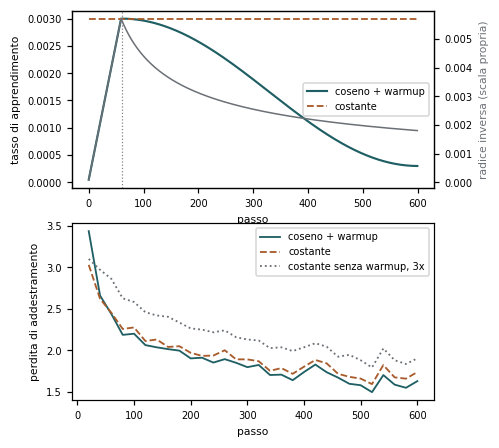

In [6]:
titolo("Le stesse cose, disegnate")
fig, ax = plt.subplots(2, 1, figsize=(stile_figure(), 4.6))
passi = range(PASSI)
ax[0].plot(passi, [coseno(p) for p in passi], lw=1.4, label="coseno + warmup")
ax[0].plot(passi, [costante(p) for p in passi], lw=1.2, ls="--", label="costante")
ax[0].axvline(WARMUP, ls=":", lw=0.8, color="gray")
ax[0].set_xlabel("passo")
ax[0].set_ylabel("tasso di apprendimento")
ax[0].legend()
ax2 = ax[0].twinx()
ax2.plot(passi, [radice_inversa(p) for p in passi], lw=1.0, color="#6B7076")
ax2.set_ylabel("radice inversa (scala propria)", color="#6B7076")
for nome, (storia, _) in risultati.items():
    ax[1].plot([20 * (i + 1) for i in range(len(storia))], storia, lw=1.2,
               label=nome)
ax[1].set_xlabel("passo")
ax[1].set_ylabel("perdita di addestramento")
ax[1].legend()
figura(fig, "05-04_schedule_lr")

## Da provare

porta il warmup a zero e confronta la perdita a venti passi.